In [1]:
# Aluno: Charles Villalba

import pandas as pd
import os
import kagglehub

# Download latest version
path = kagglehub.dataset_download("thedevastator/netflix-top-rated-movies-and-tv-shows-2020-2022")
df = pd.read_csv(os.path.join(path, "raw_titles.csv"))

# Vamos ter um preview do arquivo

In [2]:
df.head()

,index,id,title,type,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes
0,0,ts300399,Five Came Back: The Reference Films,SHOW,1945,TV-MA,48,['documentation'],['US'],1.0,NaN,NaN,NaN
1,1,tm84618,Taxi Driver,MOVIE,1976,R,113,"['crime', 'drama']",['US'],NaN,tt0075314,8.3,795222.0
2,2,tm127384,Monty Python and the Holy Grail,MOVIE,1975,PG,91,"['comedy', 'fantasy']",['GB'],NaN,tt0071853,8.2,530877.0
3,3,tm70993,Life of Brian,MOVIE,1979,R,94,['comedy'],['GB'],NaN,tt0079470,8.0,392419.0
4,4,tm190788,The Exorcist,MOVIE,1973,R,133,['horror'],['US'],NaN,tt0070047,8.1,391942.0


# Agora vamos ver o quão grande é esse dataset, ou seja, a dimensão dele

In [3]:
df.shape

(5806, 13)

# 1. Identificação: Classificar as colunas do dataset em variáveis Qualitativas (Nominais/Ordinais) e Quantitativas (Discretas/Contínuas).

In [4]:
df.columns

Index(['index', 'id', 'title', 'type', 'release_year', 'age_certification',
       'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id',
       'imdb_score', 'imdb_votes'],
      dtype='str')

In [5]:
df.dtypes

index                     int64
id                          str
title                       str
type                        str
release_year              int64
age_certification           str
runtime                   int64
genres                      str
production_countries        str
seasons                 float64
imdb_id                     str
imdb_score              float64
imdb_votes              float64
dtype: object

## Variáveis Qualitativas (Nominais/Ordinais)
Nominais: id, title, type, genres, production_countries, imdb_id.
Ordinal: age_certification. 

## Variáveis Quantitativas (Discretas/Contínuas)
Discretas: release_year, seasons, imdb_votes.
Contínuas: runtime, imdb_score.

# 2. Limpeza: Verificar se há valores nulos (missing values) e duplicados, e decidir o que fazer com eles.

## Verificar se existem valores nulos

In [6]:
df.isnull().sum()

index                      0
id                         0
title                      1
type                       0
release_year               0
age_certification       2610
runtime                    0
genres                     0
production_countries       0
seasons                 3759
imdb_id                  444
imdb_score               523
imdb_votes               539
dtype: int64

## Verificar duplicados

In [7]:
df.duplicated().sum()

np.int64(0)

## O que fazer?

In [8]:
df.isnull().sum()

index                      0
id                         0
title                      1
type                       0
release_year               0
age_certification       2610
runtime                    0
genres                     0
production_countries       0
seasons                 3759
imdb_id                  444
imdb_score               523
imdb_votes               539
dtype: int64

- Aqui podemos ver a falta de 3.759 registros sem o dado para "temporada", será que são séries sem temporadas? Vamos investigar.

In [9]:
df["type"].value_counts()

type
MOVIE    3759
SHOW     2047
Name: count, dtype: int64

- O número de filmes bateu com a quantidade de dados ausentes para temporada, logo, é o esperado, pois, filmes não possuem temporadas.

- Eu quero manter minha base a mais completa possível, desta forma removerei todos os dados ausentes em imdb_id, imdb_score, imdb_votes, age_certification, title.

In [10]:
df = df.dropna(subset=["title", "imdb_score", "imdb_votes", "age_certification" ])

df.isnull().sum()

index                      0
id                         0
title                      0
type                       0
release_year               0
age_certification          0
runtime                    0
genres                     0
production_countries       0
seasons                 1319
imdb_id                    0
imdb_score                 0
imdb_votes                 0
dtype: int64

- Vou analizar qual a quantidade que mais se perdeu ao remover os dados nulos:

In [11]:
df["type"].value_counts()

type
SHOW     1670
MOVIE    1319
Name: count, dtype: int64

In [12]:
print(f'Perdemos {3759 - 1670} filmes e {2047 - 1319} séries.')

Perdemos 2089 filmes e 728 séries.


# 3. Estatística Básica: Calcular Média, Mediana, Moda e Desvio Padrão de uma coluna numérica importante (ex: Duração do Filme, Avaliação, Preço).

- Escolherei a nota média das avaliações no imdb.
- O motivo para essa escolha é considerando que sou assinante em potencial da Netflix desejo saber se aquele serviço me fornecerá séries e filmes de qualidade, ou, se aquele acervo de mídias é minimamente agradável para a maioria das pessoas

In [13]:
media = df["imdb_score"].mean()
mediana = df["imdb_score"].median()
moda = df["imdb_score"].mode()[0]
desvio_padrao = df["imdb_score"].std()

print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Moda: {moda:.2f}")
print(f"Desvio padrão: {desvio_padrao:.2f}")

Média: 6.73
Mediana: 6.80
Moda: 6.80
Desvio padrão: 1.13


- Acima temos a média geral. Porém, eu tenho preferencia por filmes e minha esposa por séries.
- Vejamos a média baseada nas categorias.

In [14]:
movies = df[df["type"] == "MOVIE"]
shows = df[df["type"] == "SHOW"]

In [15]:
df.groupby("type")["imdb_score"].agg(
    media="mean",
    mediana="median",
    moda=lambda x: x.mode().iloc[0],
    desvio_padrao="std"
)

,media,mediana,moda,desvio_padrao
type,,,,
MOVIE,6.349659,6.4,6.3,1.086480
SHOW,7.032335,7.2,7.6,1.070021


- Podemos ver que a Netflix investe mais na curadoria de séries sendo significativamente maior em nota do que os filmes. Notícia triste para mim.

# 4. Visualização: Gerar pelo menos dois gráficos simples (exemplo: 1 Gráfico de Barras para categorias e 1 Histograma/Boxplot para distribuição numérica).

- Quero explorar aqui duas dúvidas que tenho:
  - 1) Qual a diversidade deste catálogo? Eu gosto muito de Hollywood, mas as vezes sinto falta de ver outras produções.
  - 2) Qual a média das produções baseado nos países? De nada adianta termos vários países e só os piores filmes daquela região.

In [16]:
df["production_countries"].head(10)

1     ['US']
2     ['GB']
3     ['GB']
4     ['US']
5     ['GB']
6     ['US']
7     ['US']
8     ['US']
9     ['US']
10    ['US']
Name: production_countries, dtype: str

In [17]:
# Preciso saber se existem multiplos países associados
df[df["production_countries"].str.contains(",")]["production_countries"].count()

np.int64(328)

In [18]:
# Transformarei os países em listas, assim poderemos contá-los mais facilmente.

import ast

paises = df.copy()
paises["production_countries"] = paises["production_countries"].apply(ast.literal_eval)
paises["production_countries"].head(10)


1     [US]
2     [GB]
3     [GB]
4     [US]
5     [GB]
6     [US]
7     [US]
8     [US]
9     [US]
10    [US]
Name: production_countries, dtype: object

In [19]:
paises = paises.explode("production_countries")
paises["production_countries"].value_counts()

production_countries
US    1499
GB     256
IN     236
JP     204
CA     122
      ... 
LT       1
AL       1
MU       1
MY       1
KW       1
Name: count, Length: 75, dtype: int64

In [20]:
# Agora que sabemos quantas produções temos por país, vamos seprar por tipo:
paises[["production_countries", "type"]].head(10)

,production_countries,type
1,US,MOVIE
2,GB,MOVIE
3,GB,MOVIE
4,US,MOVIE
5,GB,SHOW
6,US,MOVIE
7,US,MOVIE
8,US,MOVIE
9,US,MOVIE
10,US,MOVIE


In [21]:
# Aqui um pouco de programação: salvei a tabela inicial numa variável, a qual realizei uma soma do total de movie e show e por fim ordenei.
contagem_paises = paises.groupby(
    ["production_countries", "type"]
).size().unstack(fill_value=0)


contagem_paises["TOTAL"] = contagem_paises["MOVIE"] + contagem_paises["SHOW"]
contagem_paises.sort_values("TOTAL", ascending=False)

type,MOVIE,SHOW,TOTAL
production_countries,,,
US,780,719,1499
GB,134,122,256
IN,205,31,236
JP,63,141,204
CA,69,53,122
...,...,...,...
HR,0,1,1
GH,1,0,1
CY,1,0,1


# Gráfico 1: Quantidade de mídia por país

<Axes: xlabel='production_countries'>

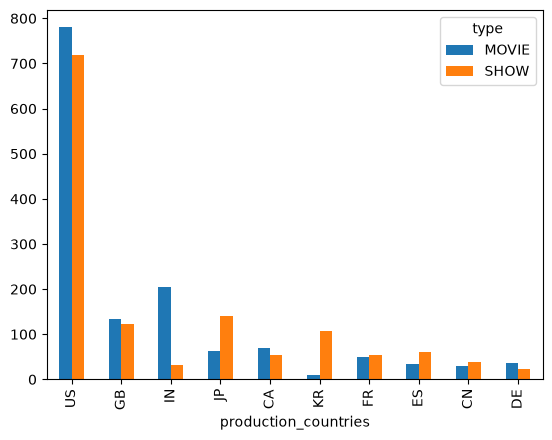

In [22]:
top10 = contagem_paises.sort_values("TOTAL", ascending=False).head(10)

top10[["MOVIE", "SHOW"]].plot(kind="bar")

# Gráfico 2: Nota média por país

In [23]:
media_por_pais = paises.groupby("production_countries")["imdb_score"].mean()

media_por_pais

production_countries
AE    5.709091
AL    6.200000
AR    6.885714
AT    7.000000
AU    6.741176
        ...   
US    6.610073
VA    6.400000
XX    6.688889
ZA    6.246667
ZW    6.100000
Name: imdb_score, Length: 75, dtype: float64

In [24]:
media_por_pais.sort_values(ascending=False)

production_countries
GH    7.700000
IL    7.466667
HR    7.400000
KR    7.375214
PT    7.333333
        ...   
SY    5.400000
RO    5.200000
KW    5.200000
LT    4.700000
CY    2.900000
Name: imdb_score, Length: 75, dtype: float64

In [25]:
analise_paises = paises.groupby(
    ["production_countries", "type"]
)["imdb_score"].agg(["count", "mean"])

analise_paises.sort_values("count", ascending=False)

count      mean
production_countries type                  
US                   MOVIE    780  6.278846
                     SHOW     719  6.969402
IN                   MOVIE    205  6.671220
JP                   SHOW     141  7.256028
GB                   MOVIE    134  6.538806
...                           ...       ...
PT                   MOVIE      1  6.600000
RS                   MOVIE      1  6.400000
MA                   MOVIE      1  5.500000
SA                   MOVIE      1  5.900000
ZW                   MOVIE      1  6.100000

[125 rows x 2 columns]

In [26]:
top10.index

Index(['US', 'GB', 'IN', 'JP', 'CA', 'KR', 'FR', 'ES', 'CN', 'DE'], dtype='str', name='production_countries')

In [27]:
# Agora podemos ter uma visão melhor de quais países mais possuem produção e suas respectivas notas médias em cada tipo

analise_top10 = analise_paises.loc[top10.index]
analise_top10

count      mean
production_countries type                  
US                   MOVIE    780  6.278846
                     SHOW     719  6.969402
GB                   MOVIE    134  6.538806
                     SHOW     122  7.195902
IN                   MOVIE    205  6.671220
                     SHOW      31  6.977419
JP                   MOVIE     63  6.769841
                     SHOW     141  7.256028
CA                   MOVIE     69  6.065217
                     SHOW      53  7.043396
KR                   MOVIE      9  6.511111
                     SHOW     108  7.447222
FR                   MOVIE     50  6.360000
                     SHOW      53  6.958491
ES                   MOVIE     35  6.500000
                     SHOW      61  6.724590
CN                   MOVIE     30  6.333333
                     SHOW      38  7.457895
DE                   MOVIE     37  6.462162
                     SHOW      22  7.240909

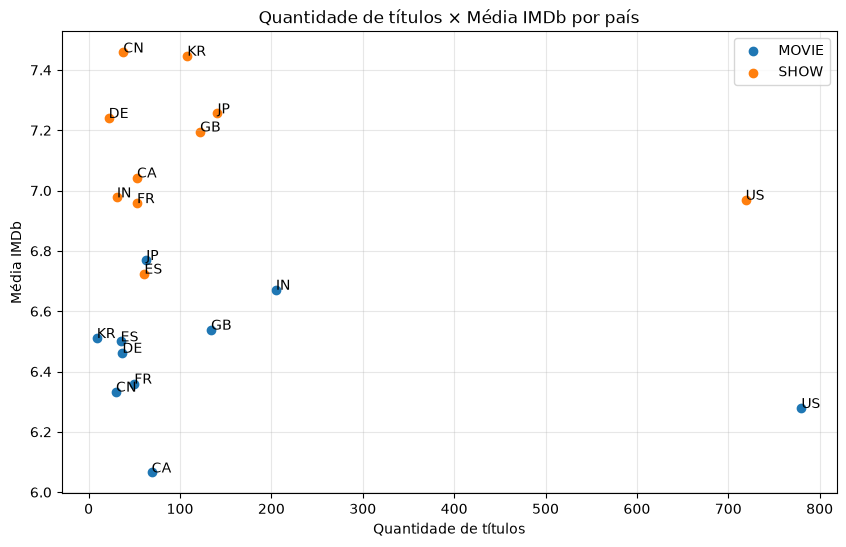

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for tipo in ["MOVIE", "SHOW"]:
    dados = analise_top10.xs(tipo, level="type")

    plt.scatter(
        dados["count"],
        dados["mean"],
        label=tipo
    )

    # Identifica cada ponto pelo país
    for pais, linha in dados.iterrows():
        plt.annotate(
            pais,
            (linha["count"], linha["mean"])
        )

plt.title("Quantidade de títulos × Média IMDb por país")
plt.xlabel("Quantidade de títulos")
plt.ylabel("Média IMDb")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# 5. Conclusão: Escrever 2 insights simples baseados nas análises realizadas.

A partir das análises, podemos concluir que:

1) O catálogo da Netflix realmente possui uma curadoria que preza a qualidade e diversidade. Entretanto, existe uma clara preferência por séries de melhor qualidade à filmes de melhor qualidade.
3) Apesar da maior quantidade de produções norte-americanas, quase todos as séries e filmes de outros países possuem notas melhores que as produções norte-americanas.